Training dataset X:
[[ 0.3190391  -1.07296862  0.86540763 -0.17242821  1.14472371  0.50249434
  -2.3015387  -0.68372786 -0.38405435 -0.87785842 -2.06014071 -1.10061918
  -1.09989127  1.13376944  1.74481176 -0.12289023 -0.93576943  1.62434536
   1.46210794  0.90159072 -0.7612069   0.53035547 -0.52817175 -0.26788808
   0.58281521  0.04221375  0.90085595 -0.24937038 -0.61175641 -0.3224172 ]]
Training dataset Y:
[[ -3.01854669 -65.65047675  26.96755728   8.70562603  57.94332628
   -0.69293498 -78.66594473 -12.73881492 -13.26721663 -24.80488085
  -74.24484385 -39.99533724 -22.70174437  73.46766345  55.7257405
   23.80417646 -13.45481508  25.57952246  75.91238321  50.91155323
  -43.7191551   -1.7025559  -16.44931235 -33.54041234  20.4505961
   18.35949302  37.69029586  -1.04801683  -4.47915933 -20.89431647]]
The size of the input layer is: n_x = 1
The size of the output layer is: n_y = 1
W = [[0.01072209]]
b = [[0.]]
[[ 0.00342077 -0.01150447  0.00927898 -0.00184879  0.01227383  0.00538779
 

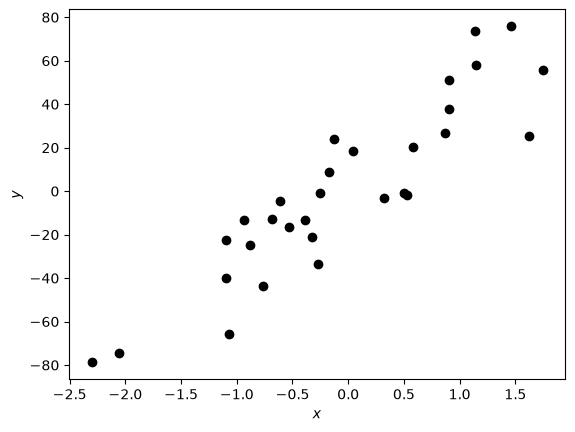

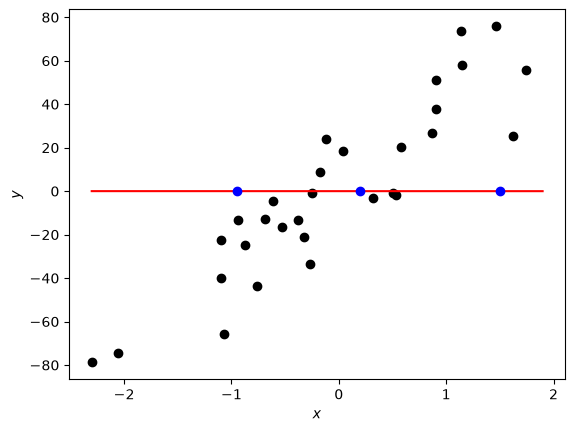

In [9]:

from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np
X, Y = make_regression(n_samples=30, n_features=1, noise=20, random_state=1)

X = X.T
Y = Y.reshape(1, -1)

print("Training dataset X:")
print(X)
print("Training dataset Y:")
print(Y)

plt.scatter(X,  Y, c="black")

plt.xlabel("$x$")
plt.ylabel("$y$")

def layer_sizes(X, Y):
    n_x=X.shape[0]
    n_y=Y.shape[0]

    return (n_x,n_y)

(n_x, n_y) = layer_sizes(X, Y)
print("The size of the input layer is: n_x = " + str(n_x))
print("The size of the output layer is: n_y = " + str(n_y))

def initialize_parameters(n_x, n_y):
    W=np.random.randn(n_y,n_x) * 0.01
    b=np.zeros((n_y,1))
    assert (W.shape == (n_y, n_x))
    assert (b.shape == (n_y, 1))
    parameters={
        'W':W,
        'b':b
    }
    return parameters

parameters = initialize_parameters(n_x, n_y)
print("W = " + str(parameters["W"]))
print("b = " + str(parameters["b"]))

def forward_propagation(X, parameters):
    W=parameters.get('W')
    b=parameters.get('b')
    assert(W.shape[1] == X.shape[0])
    Z=np.matmul(W,X)+b
    y_hat=Z

    assert (y_hat.shape == (W.shape[0], X.shape[1]))

    return y_hat

Y_hat = forward_propagation(X, parameters)

print(Y_hat)

def compute_cost(Y_hat,Y):
    m=Y.shape[1]
    cost=np.sum((Y_hat-Y)**2)/2*m
    return cost

print("cost = " + str(compute_cost(Y_hat, Y)))

def nn_model(X, Y, num_iterations=10, print_cost=False):
    n_x=layer_sizes(X,Y)[0]
    n_y=layer_sizes(X,Y)[1]

    parameters=initialize_parameters(n_x,n_y)

    for i in range(0,num_iterations):
        Y_hat=forward_propagation(X,parameters)

        cost=compute_cost(Y_hat,Y)
        if print_cost:
            print ("Cost after iteration %i: %f" %(i, cost))

    return parameters

parameters = nn_model(X, Y, num_iterations=15, print_cost=True)
print("W = " + str(parameters["W"]))
print("b = " + str(parameters["b"]))

W_simple = parameters["W"]
b_simple = parameters["b"]

X_pred = np.array([-0.95, 0.2, 1.5])

fig, ax = plt.subplots()
plt.scatter(X, Y, color = "black")

plt.xlabel("$x$")
plt.ylabel("$y$")
    
X_line = np.arange(np.min(X[0,:]),np.max(X[0,:])*1.1, 0.1)
ax.plot(X_line, W_simple[0,0] * X_line + b_simple[0,0], "r")
ax.plot(X_pred, W_simple[0,0] * X_pred + b_simple[0,0], "bo")
plt.plot()
plt.show()


